In [29]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mode
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.cluster.hierarchy import fcluster
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


In [30]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.8)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_antibiotics_count', 'sensitive_microorganism_ratio')]

In [31]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])
profile_df=profile_df.drop(columns=['max_wbc count'])

# Identifica colonne categoriche da escludere
categorical_cols = ['subject_id', 'gender', 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction']

# Seleziona solo le colonne numeriche per il clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]

# Verifica le colonne numeriche selezionate
print("Colonne numeriche per clustering:")
print(numeric_cols)
print(f"\nNumero di features: {len(numeric_cols)}")

Colonne numeriche per clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'abnormal_lab_event_ratio', 'resistant_microorganism_ratio', 'intermediate_microorganism_ratio', 'sensitive_microorganism_ratio']

Numero di features: 24


# Hierarchical clustering

In [32]:
x=scaler = StandardScaler()
X = scaler.fit_transform(profile_df[numeric_cols].values)

In [33]:
def get_cophenetic_coefficients(X, methods=['single', 'complete', 'average', 'ward']) -> pd.DataFrame:
    """ 
    Calcola i coefficienti cophenetic per i vari metodi di clustering.
    """
    cophenetic_coefficients_df = pd.DataFrame()

    for method in methods:
        Z = linkage(X, method)
        cophenetic_coefficients, _ = cophenet(Z, pdist(X, metric='euclidean'))
        
        cophenetic_coefficients_df[method] = [cophenetic_coefficients]
    
    return cophenetic_coefficients_df

# Usa X che contiene i dati già scalati con MinMaxScaler
get_cophenetic_coefficients(X)

,single,complete,average,ward
0,0.916288,0.79575,0.911497,0.490332


### il milgior metodo risulta essere average linkage

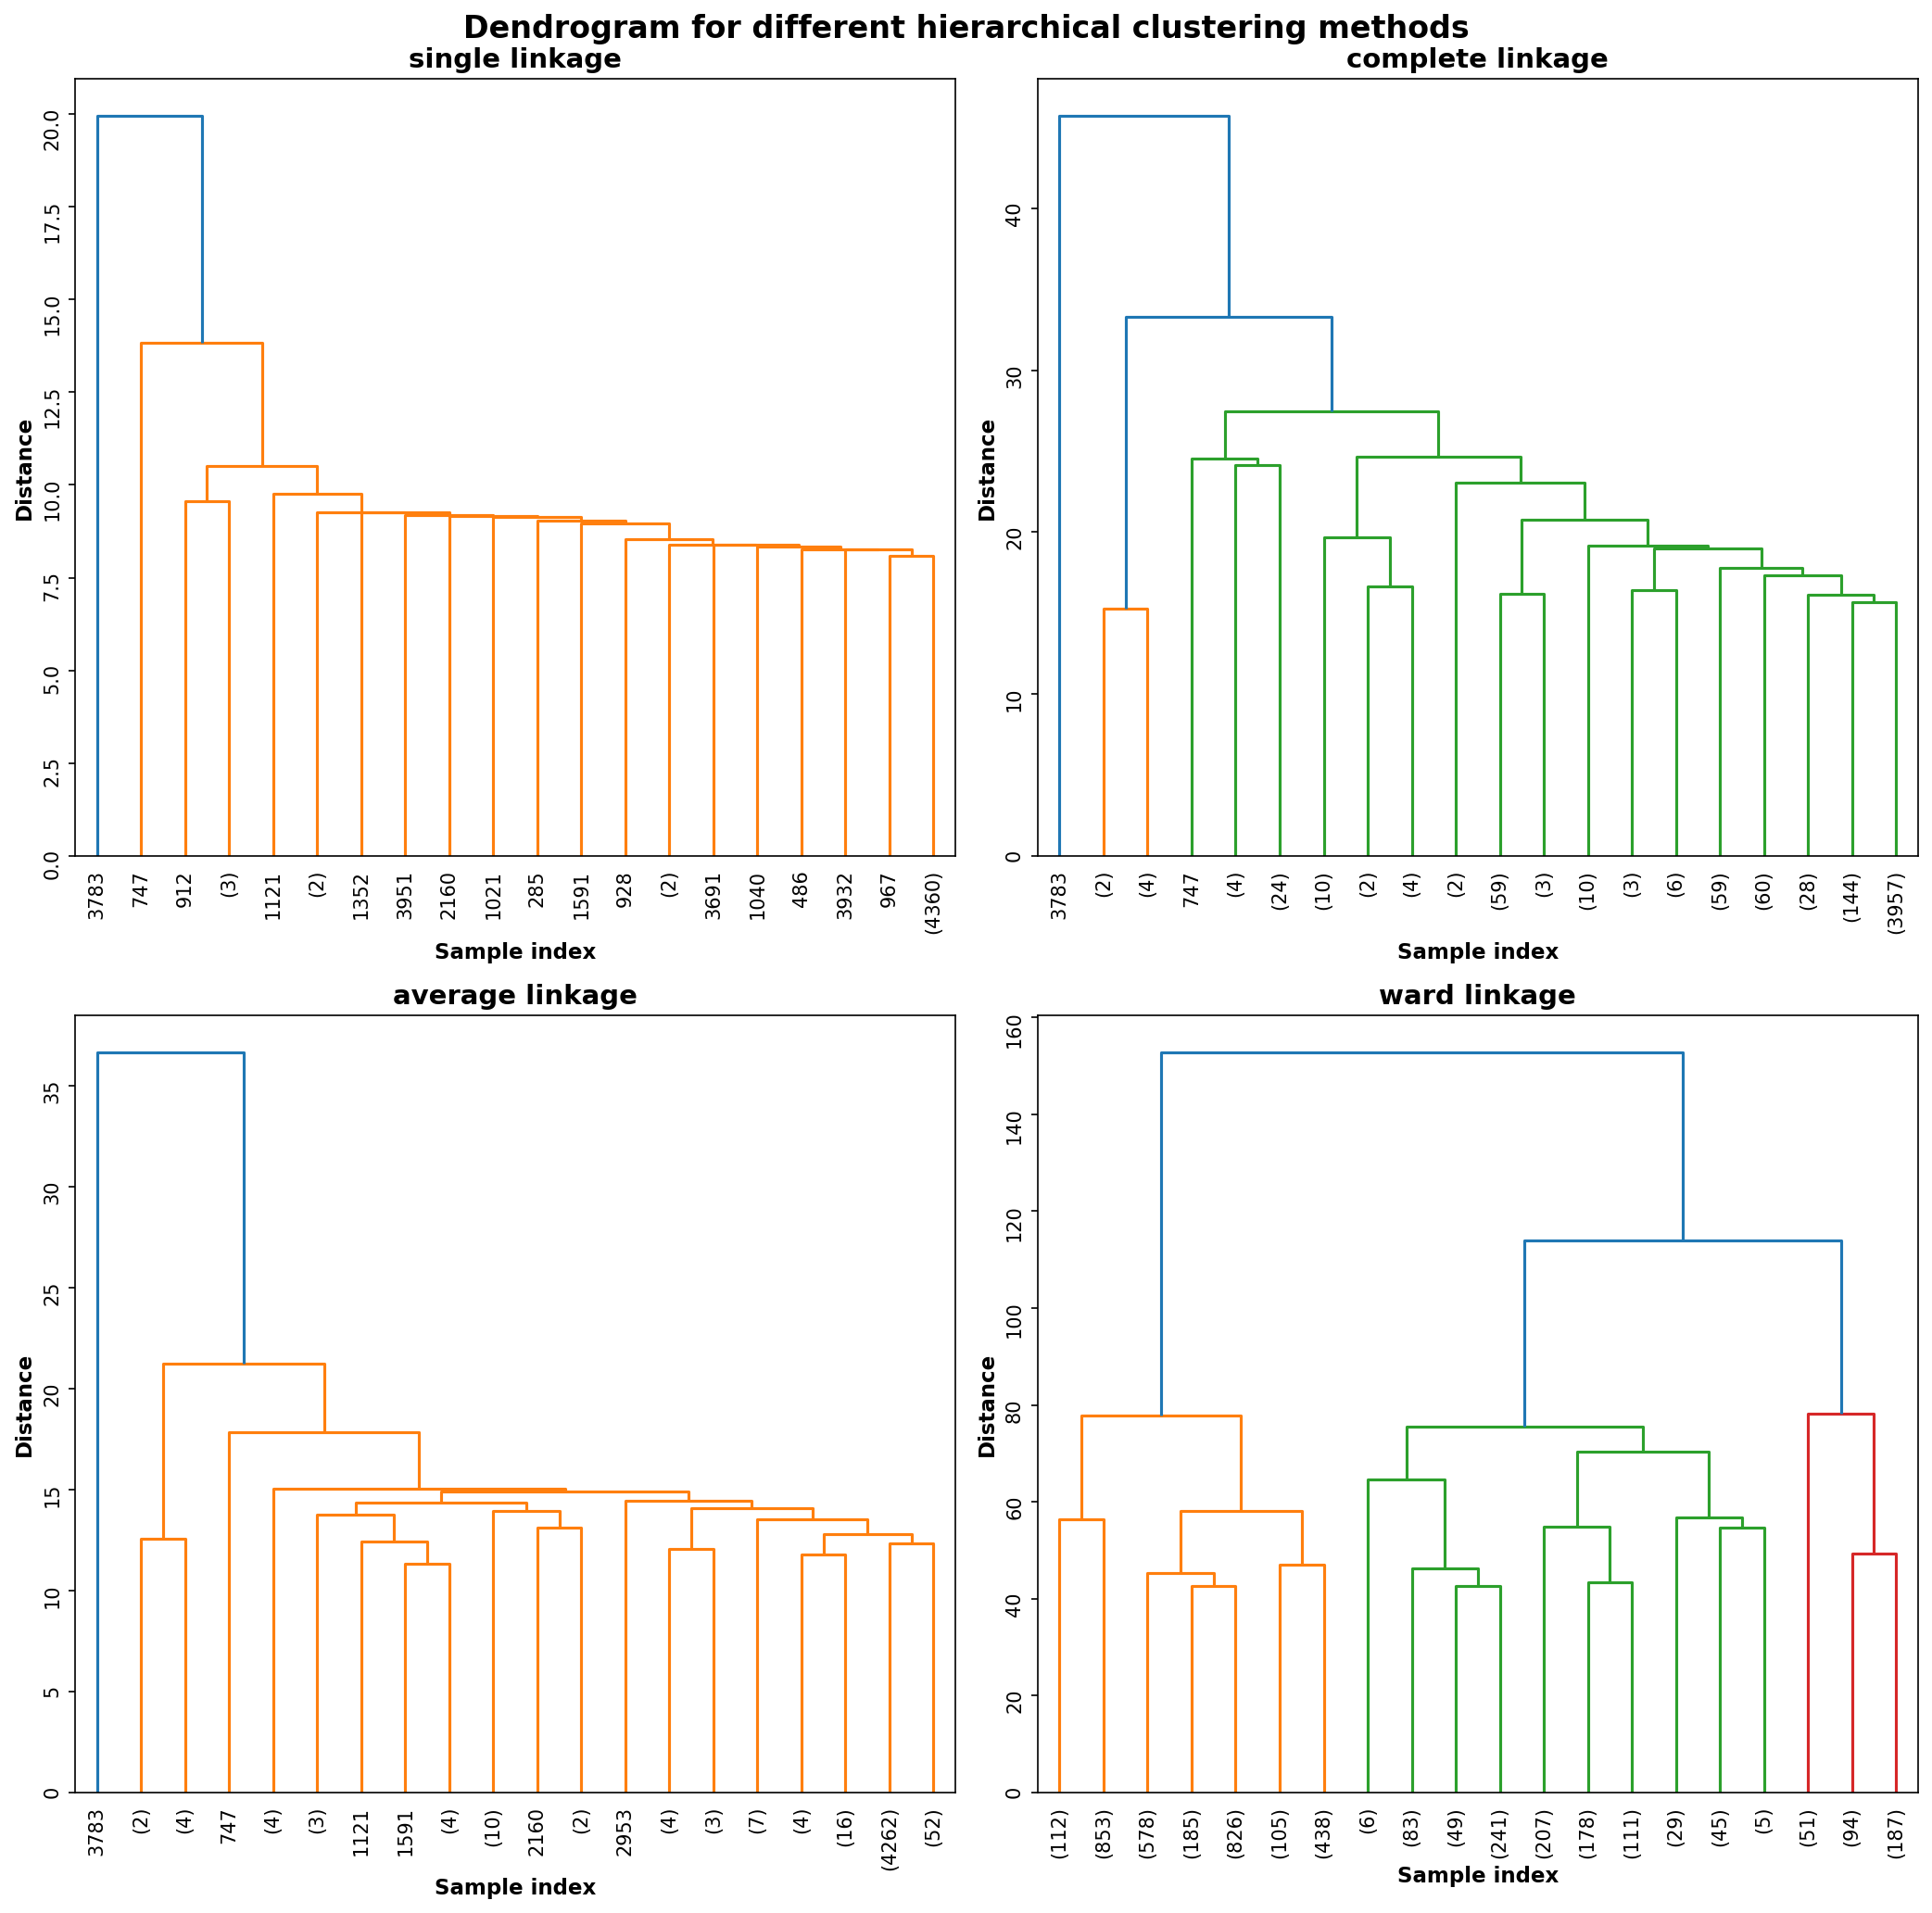

In [34]:
# Definisci i metodi di linkage da confrontare
methods = ['single', 'complete', 'average', 'ward']

fig, axs = plt.subplots(2, 2, figsize=(14, 14), dpi=150)

for ax, method in zip(axs.flatten(), methods):
    data_dist = pdist(X, metric='euclidean')
    data_link = linkage(data_dist, method=method, metric='euclidean')
    res = dendrogram(data_link, truncate_mode='lastp', ax=ax, p=20)
    ax.set_title(f'{method} linkage', fontsize=14, fontweight='bold')
    ax.tick_params(labelrotation=90, labelsize=10)
    ax.set_xlabel('Sample index', fontsize=11, fontweight='bold')
    ax.set_ylabel('Distance', fontsize=11, fontweight='bold')

fig.suptitle("Dendrogram for different hierarchical clustering methods", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### dai cophenet coefficent, avarage risulta il milgiore; gaurdando i dendogrammi ward sembra più robusto. Eseguiamo entrambi i metodi


Metodo: WARD
k=2: Silhouette=0.2442, CH=546.82
k=3: Silhouette=0.2383, CH=456.90
k=4: Silhouette=0.2441, CH=368.60
k=5: Silhouette=0.0155, CH=327.77
k=6: Silhouette=0.0246, CH=303.63
k=7: Silhouette=0.0318, CH=285.13
k=8: Silhouette=0.0342, CH=268.96
k=9: Silhouette=0.0357, CH=253.70
k=10: Silhouette=0.0377, CH=241.78
k=11: Silhouette=0.0346, CH=232.66
k=12: Silhouette=0.0407, CH=225.08
k=13: Silhouette=0.0419, CH=219.27
k=14: Silhouette=0.0441, CH=212.53
k=15: Silhouette=0.0464, CH=206.16
k=16: Silhouette=0.0494, CH=200.70
k=17: Silhouette=0.0486, CH=195.82
k=18: Silhouette=0.0515, CH=191.12
k=19: Silhouette=0.0539, CH=186.93

Cophenetic Correlation Coefficient: 0.4903

Metodo: AVERAGE
k=2: Silhouette=0.8278, CH=55.61
k=3: Silhouette=0.7047, CH=78.54
k=4: Silhouette=0.6504, CH=56.80
k=5: Silhouette=0.5857, CH=51.12
k=6: Silhouette=0.5721, CH=65.72
k=7: Silhouette=0.5538, CH=56.26
k=8: Silhouette=0.5475, CH=51.06
k=9: Silhouette=0.5398, CH=50.09
k=10: Silhouette=0.5378, CH=45.82
k=11:

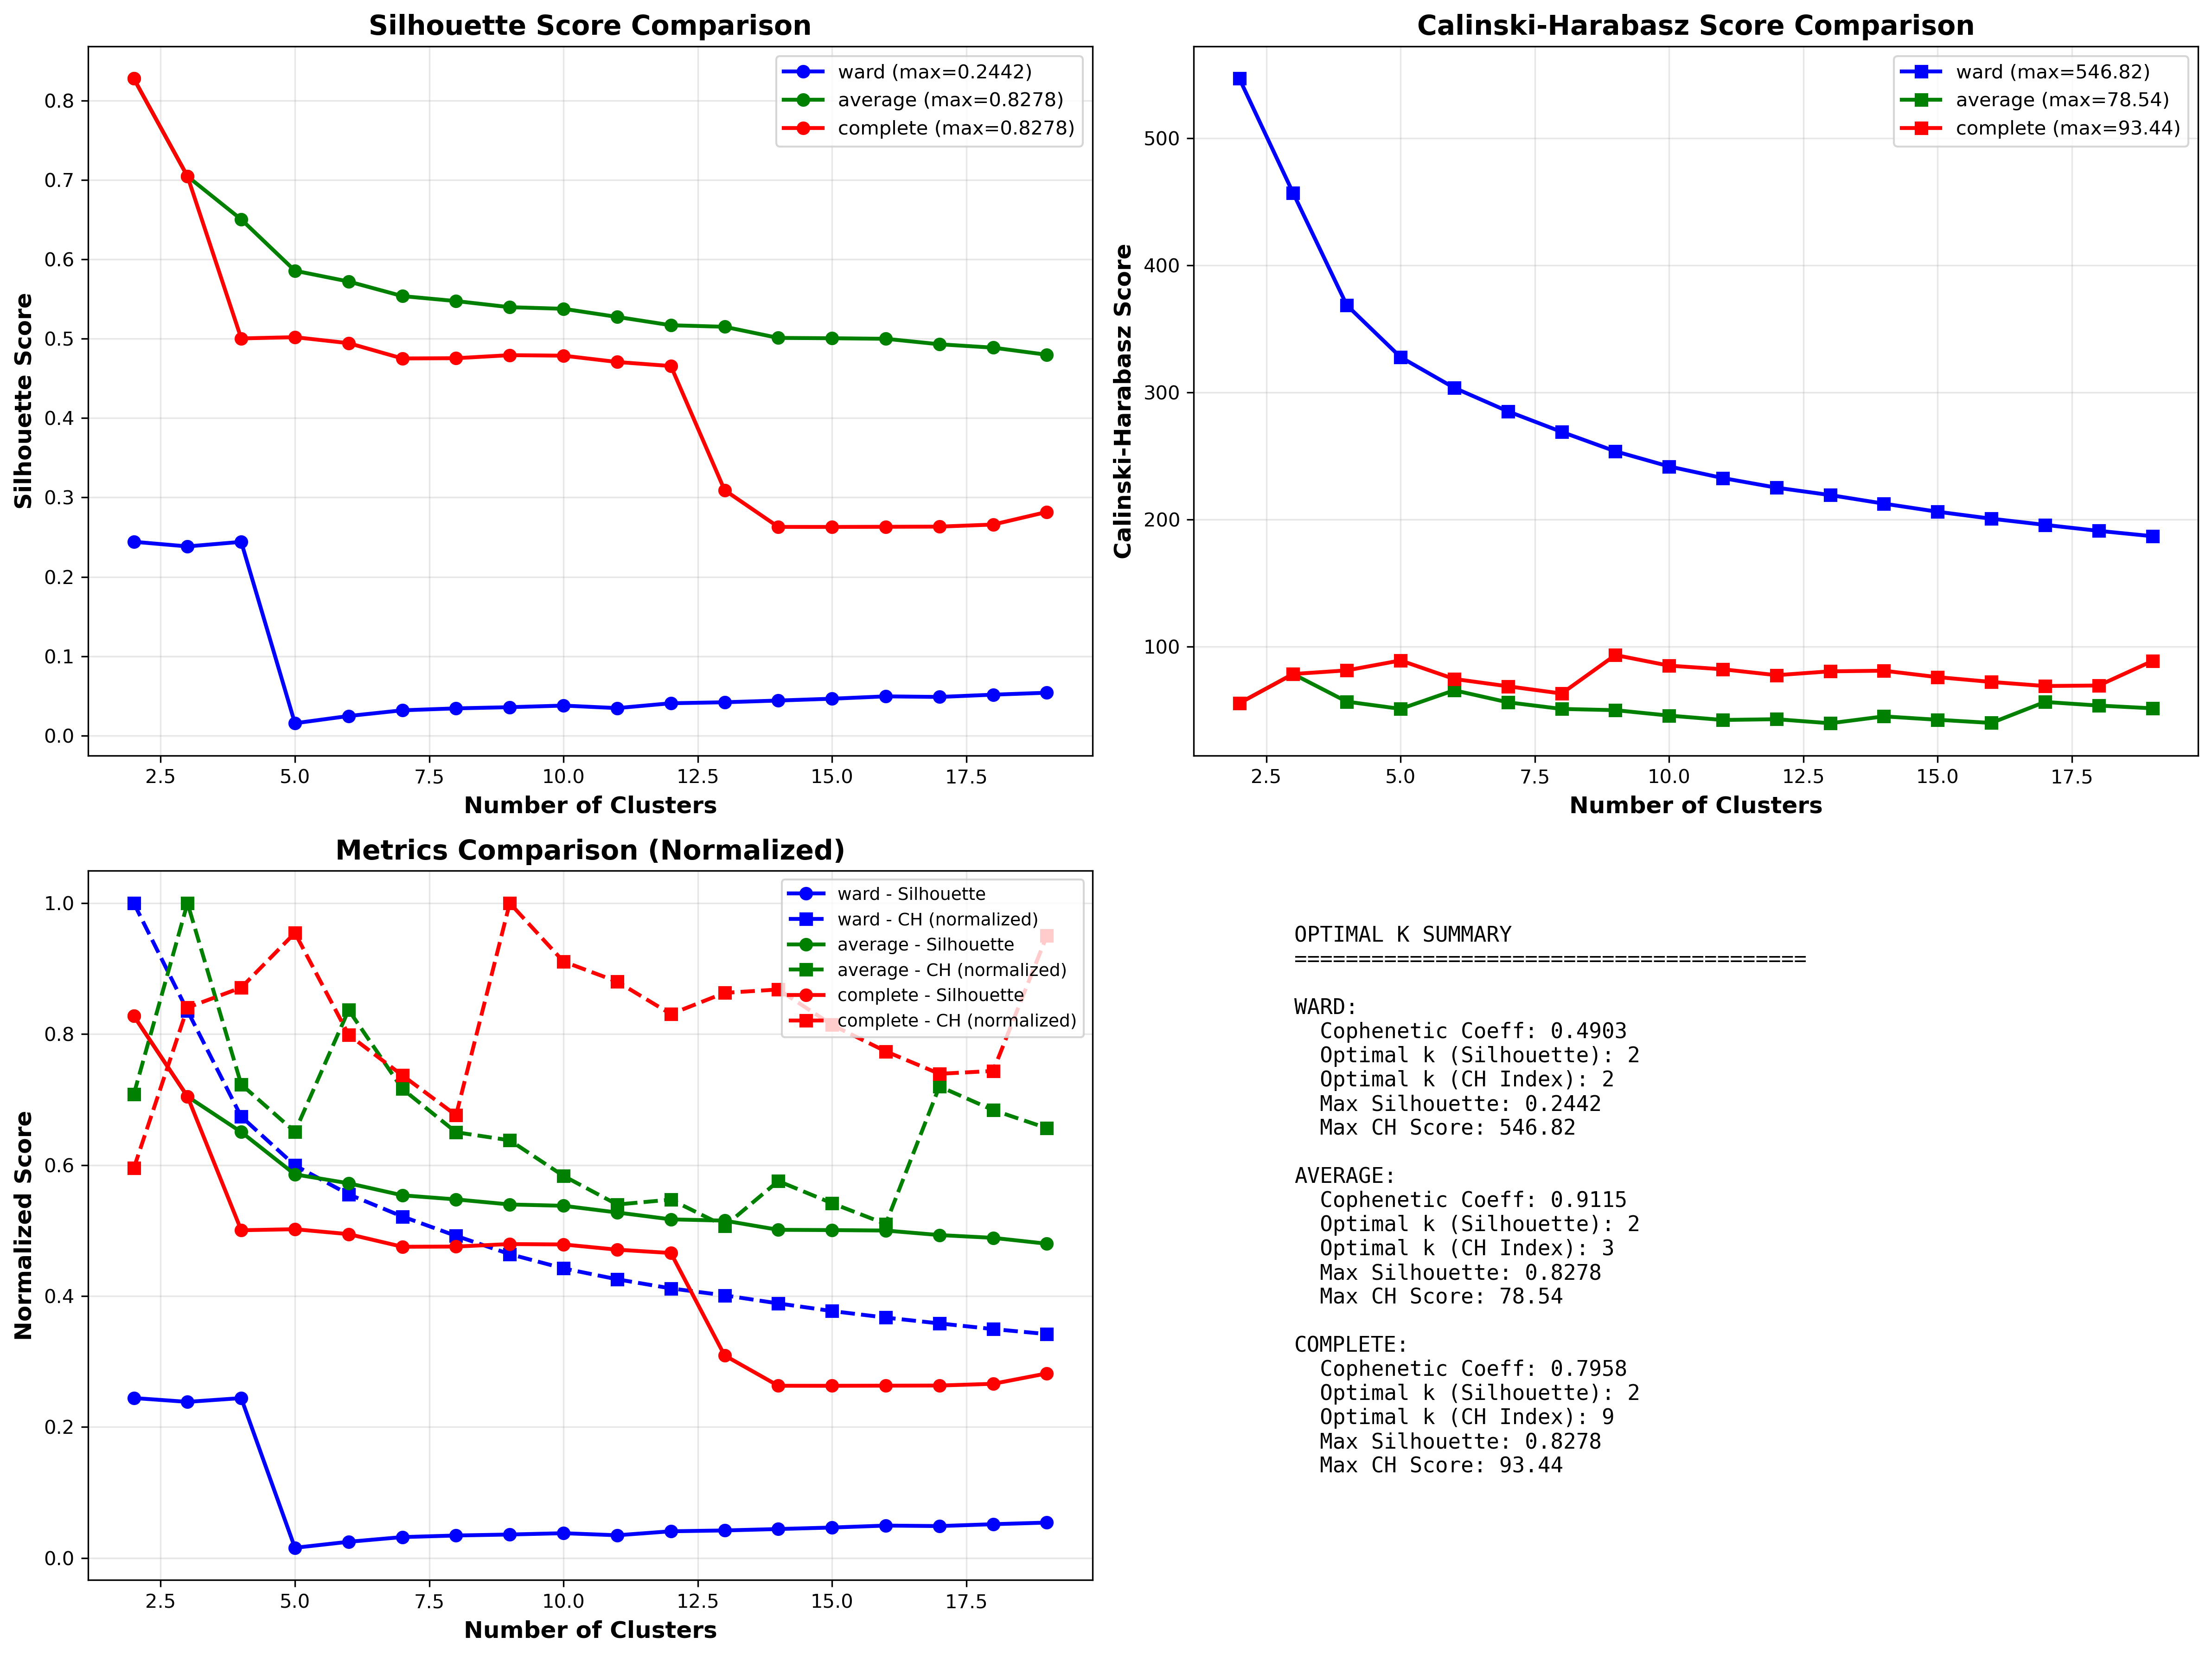


FINAL SUMMARY
OPTIMAL K SUMMARY

WARD:
  Cophenetic Coeff: 0.4903
  Optimal k (Silhouette): 2
  Optimal k (CH Index): 2
  Max Silhouette: 0.2442
  Max CH Score: 546.82

AVERAGE:
  Cophenetic Coeff: 0.9115
  Optimal k (Silhouette): 2
  Optimal k (CH Index): 3
  Max Silhouette: 0.8278
  Max CH Score: 78.54

COMPLETE:
  Cophenetic Coeff: 0.7958
  Optimal k (Silhouette): 2
  Optimal k (CH Index): 9
  Max Silhouette: 0.8278
  Max CH Score: 93.44




In [51]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import cophenet

# Metodi da confrontare
methods_to_compare = ['ward', 'average','complete']
k_range = range(2, 20)

# Dizionari per salvare i risultati
results = {}

# Calcola le metriche per ogni metodo
for method in methods_to_compare:
    print(f"\n{'='*60}")
    print(f"Metodo: {method.upper()}")
    print(f"{'='*60}")
    
    # Crea il linkage con il metodo corrente
    data_dist = pdist(X, metric='euclidean')
    data_link = linkage(data_dist, method=method, metric='euclidean')
    
    silhouette_scores = []
    calinski_harabasz_scores = []
    
    # Calcola le metriche per ogni k
    for k in k_range:
        cluster_labels = fcluster(data_link, t=k, criterion='maxclust')
        
        sil_score = silhouette_score(X, cluster_labels, metric='euclidean')
        ch_score = calinski_harabasz_score(X, cluster_labels)
        
        silhouette_scores.append(sil_score)
        calinski_harabasz_scores.append(ch_score)
        
        print(f"k={k}: Silhouette={sil_score:.4f}, CH={ch_score:.2f}")
    
    # Calcola il Cophenetic Correlation Coefficient
    coph_corr, coph_dists = cophenet(data_link, data_dist)
    print(f"\nCophenetic Correlation Coefficient: {coph_corr:.4f}")
    
    # Salva i risultati
    results[method] = {
        'silhouette': silhouette_scores,
        'calinski_harabasz': calinski_harabasz_scores,
        'cophenetic': coph_corr,
        'linkage': data_link
    }

# Visualizza il confronto
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=300)

colors = {'ward': 'blue', 'average': 'green', 'complete': 'red'}

# Plot 1: Silhouette Score
for method in methods_to_compare:
    axes[0, 0].plot(k_range, results[method]['silhouette'], 
                    marker='o', linewidth=2, markersize=6, 
                    label=f'{method} (max={max(results[method]["silhouette"]):.4f})',
                    color=colors[method])
axes[0, 0].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Silhouette Score', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Silhouette Score Comparison', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# Plot 2: Calinski-Harabasz Score
for method in methods_to_compare:
    axes[0, 1].plot(k_range, results[method]['calinski_harabasz'], 
                    marker='s', linewidth=2, markersize=6, 
                    label=f'{method} (max={max(results[method]["calinski_harabasz"]):.2f})',
                    color=colors[method])
axes[0, 1].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Calinski-Harabasz Score', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Calinski-Harabasz Score Comparison', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# Plot 3: Normalized Comparison
for method in methods_to_compare:
    sil_norm = np.array(results[method]['silhouette'])
    axes[1, 0].plot(k_range, sil_norm, 
                    marker='o', linewidth=2, markersize=6, 
                    label=f'{method} - Silhouette',
                    color=colors[method], linestyle='-')
    
    ch_norm = np.array(results[method]['calinski_harabasz']) / np.max(results[method]['calinski_harabasz'])
    axes[1, 0].plot(k_range, ch_norm, 
                    marker='s', linewidth=2, markersize=6, 
                    label=f'{method} - CH (normalized)',
                    color=colors[method], linestyle='--')

axes[1, 0].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Normalized Score', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Metrics Comparison (Normalized)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend(fontsize=9)

# Plot 4: Summary with optimal k
optimal_ks = {}
for method in methods_to_compare:
    optimal_k_sil = k_range[np.argmax(results[method]['silhouette'])]
    optimal_k_ch = k_range[np.argmax(results[method]['calinski_harabasz'])]
    optimal_ks[method] = {'silhouette': optimal_k_sil, 'calinski_harabasz': optimal_k_ch}

# Tabella riepilogativa
summary_text = "OPTIMAL K SUMMARY\n" + "="*40 + "\n\n"
for method in methods_to_compare:
    summary_text += f"{method.upper()}:\n"
    summary_text += f"  Cophenetic Coeff: {results[method]['cophenetic']:.4f}\n"
    summary_text += f"  Optimal k (Silhouette): {optimal_ks[method]['silhouette']}\n"
    summary_text += f"  Optimal k (CH Index): {optimal_ks[method]['calinski_harabasz']}\n"
    summary_text += f"  Max Silhouette: {max(results[method]['silhouette']):.4f}\n"
    summary_text += f"  Max CH Score: {max(results[method]['calinski_harabasz']):.2f}\n\n"

axes[1, 1].text(0.1, 0.5, summary_text, fontsize=11, family='monospace',
                verticalalignment='center', transform=axes[1, 1].transAxes)
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print("FINAL SUMMARY")
print(f"{'='*60}")
print(summary_text)

### avarage mostra delle silhouette nettamente milgiori,MA avarage crea cluster non adatti (1 paziente per esempio) scegliamo WARD

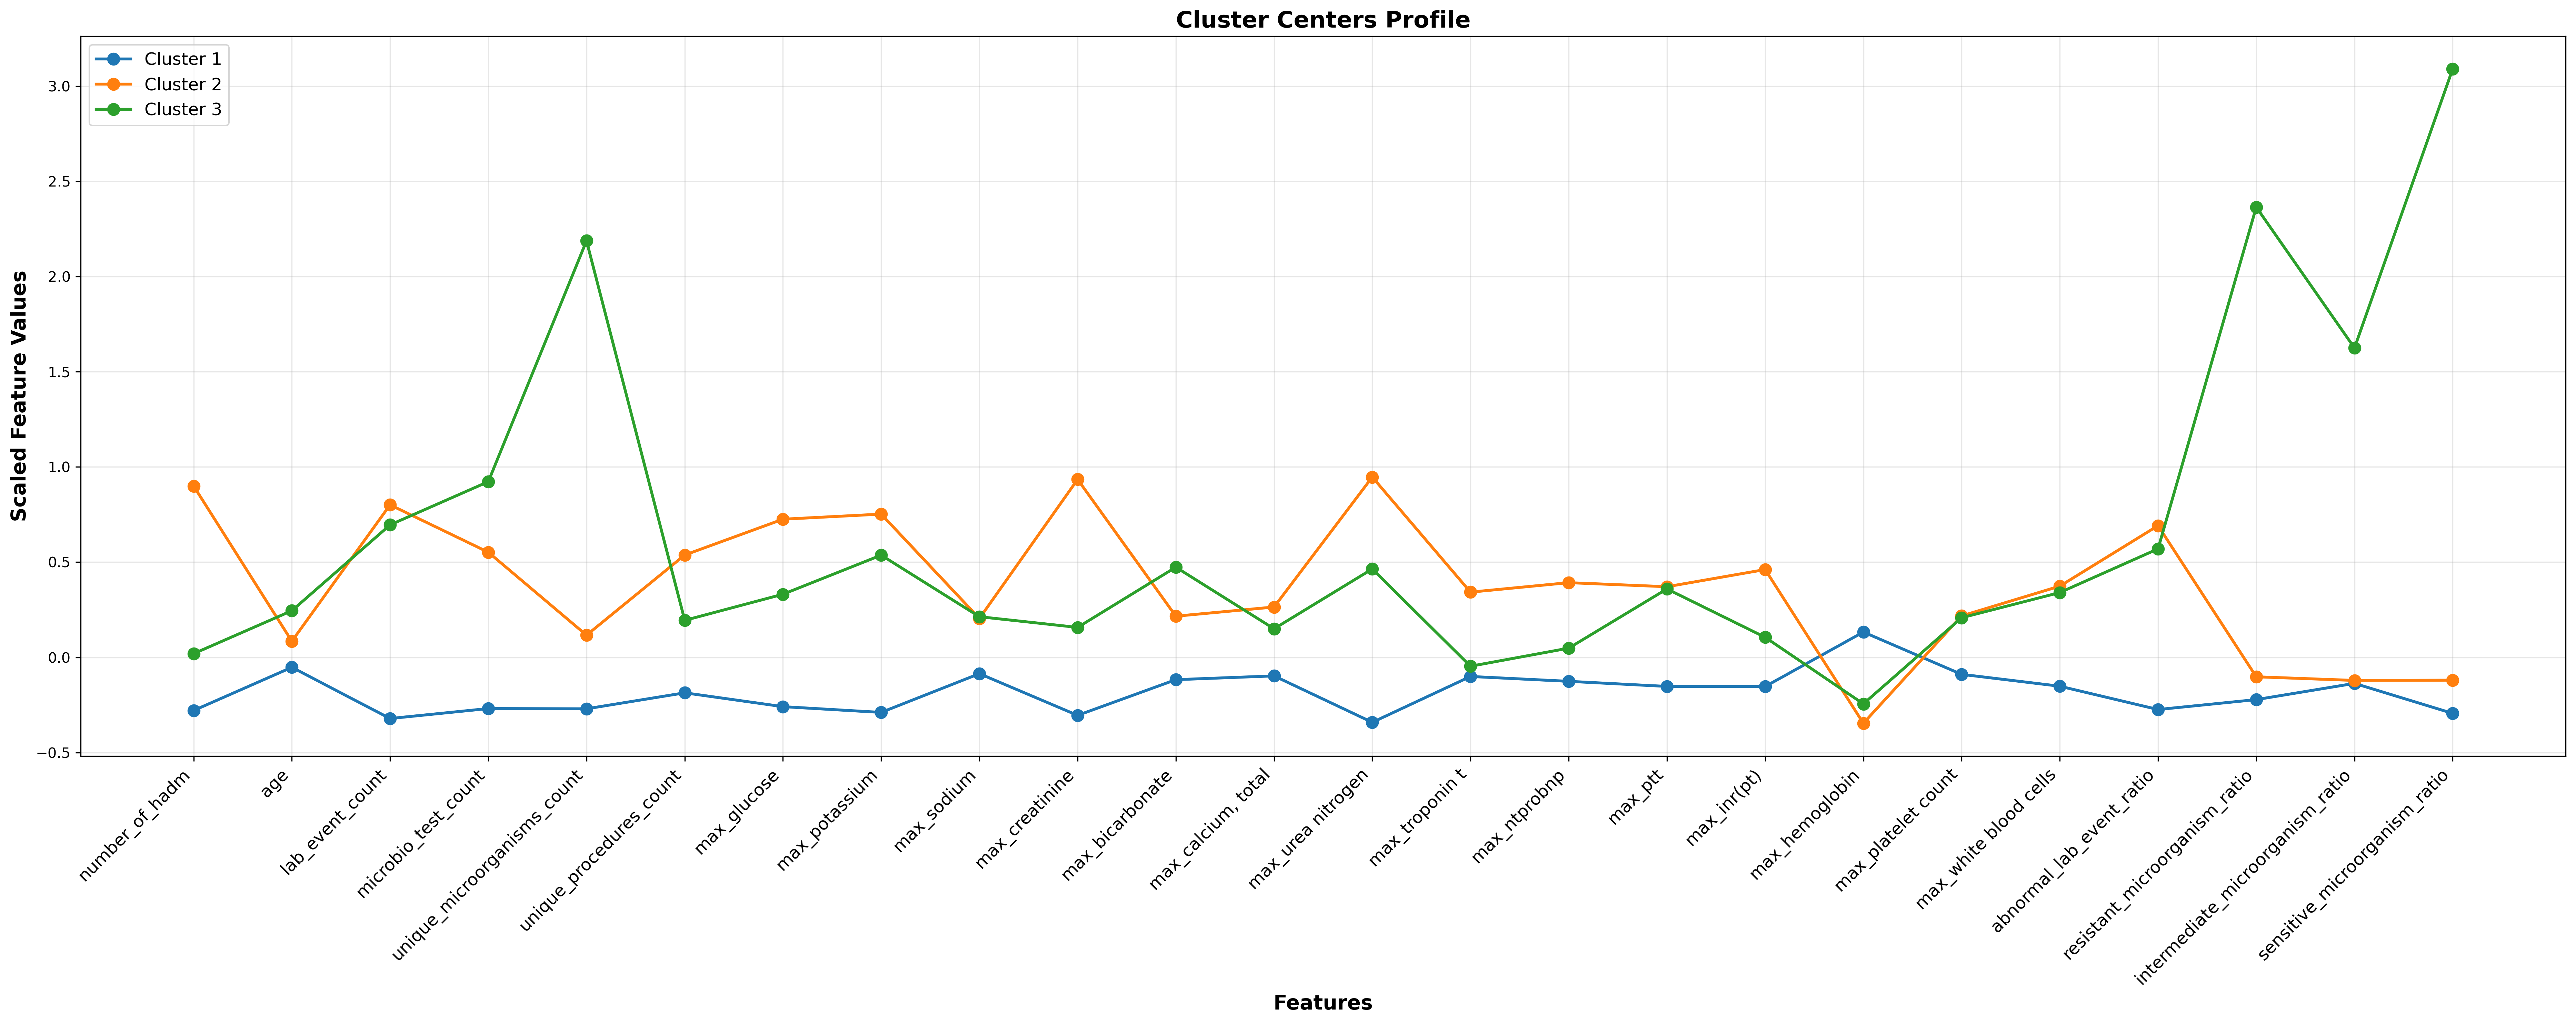

In [56]:
used_k = 3

chosen_method = 'ward'  
data_link = results[chosen_method]['linkage']

# Get cluster labels
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')

# Add cluster labels to the dataframe
profile_df['cluster'] = cluster_labels

# Compute cluster centers (mean of each feature per cluster)
# Use the scaled data X and the numeric column names
feature_names = list(numeric_cols)

# Calculate centers for each cluster
centers = []
for cluster_id in range(1, used_k + 1):
    cluster_mask = cluster_labels == cluster_id
    cluster_center = X[cluster_mask].mean(axis=0)
    centers.append(cluster_center)

centers = np.array(centers)

# Plot cluster centers
plt.figure(figsize=(25, 10), dpi=300)
for i in range(len(centers)):
    plt.plot(centers[i], marker='o', label='Cluster %s' % (i + 1), linewidth=2, markersize=8)

plt.tick_params(axis='both', which='major', labelsize=10)
plt.xticks(range(len(feature_names)), feature_names, fontsize=12, rotation=45, ha='right')
plt.xlabel('Features', fontsize=14, fontweight='bold')
plt.ylabel('Scaled Feature Values', fontsize=14, fontweight='bold')
plt.title('Cluster Centers Profile', fontsize=16, fontweight='bold')
plt.legend(fontsize=12, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

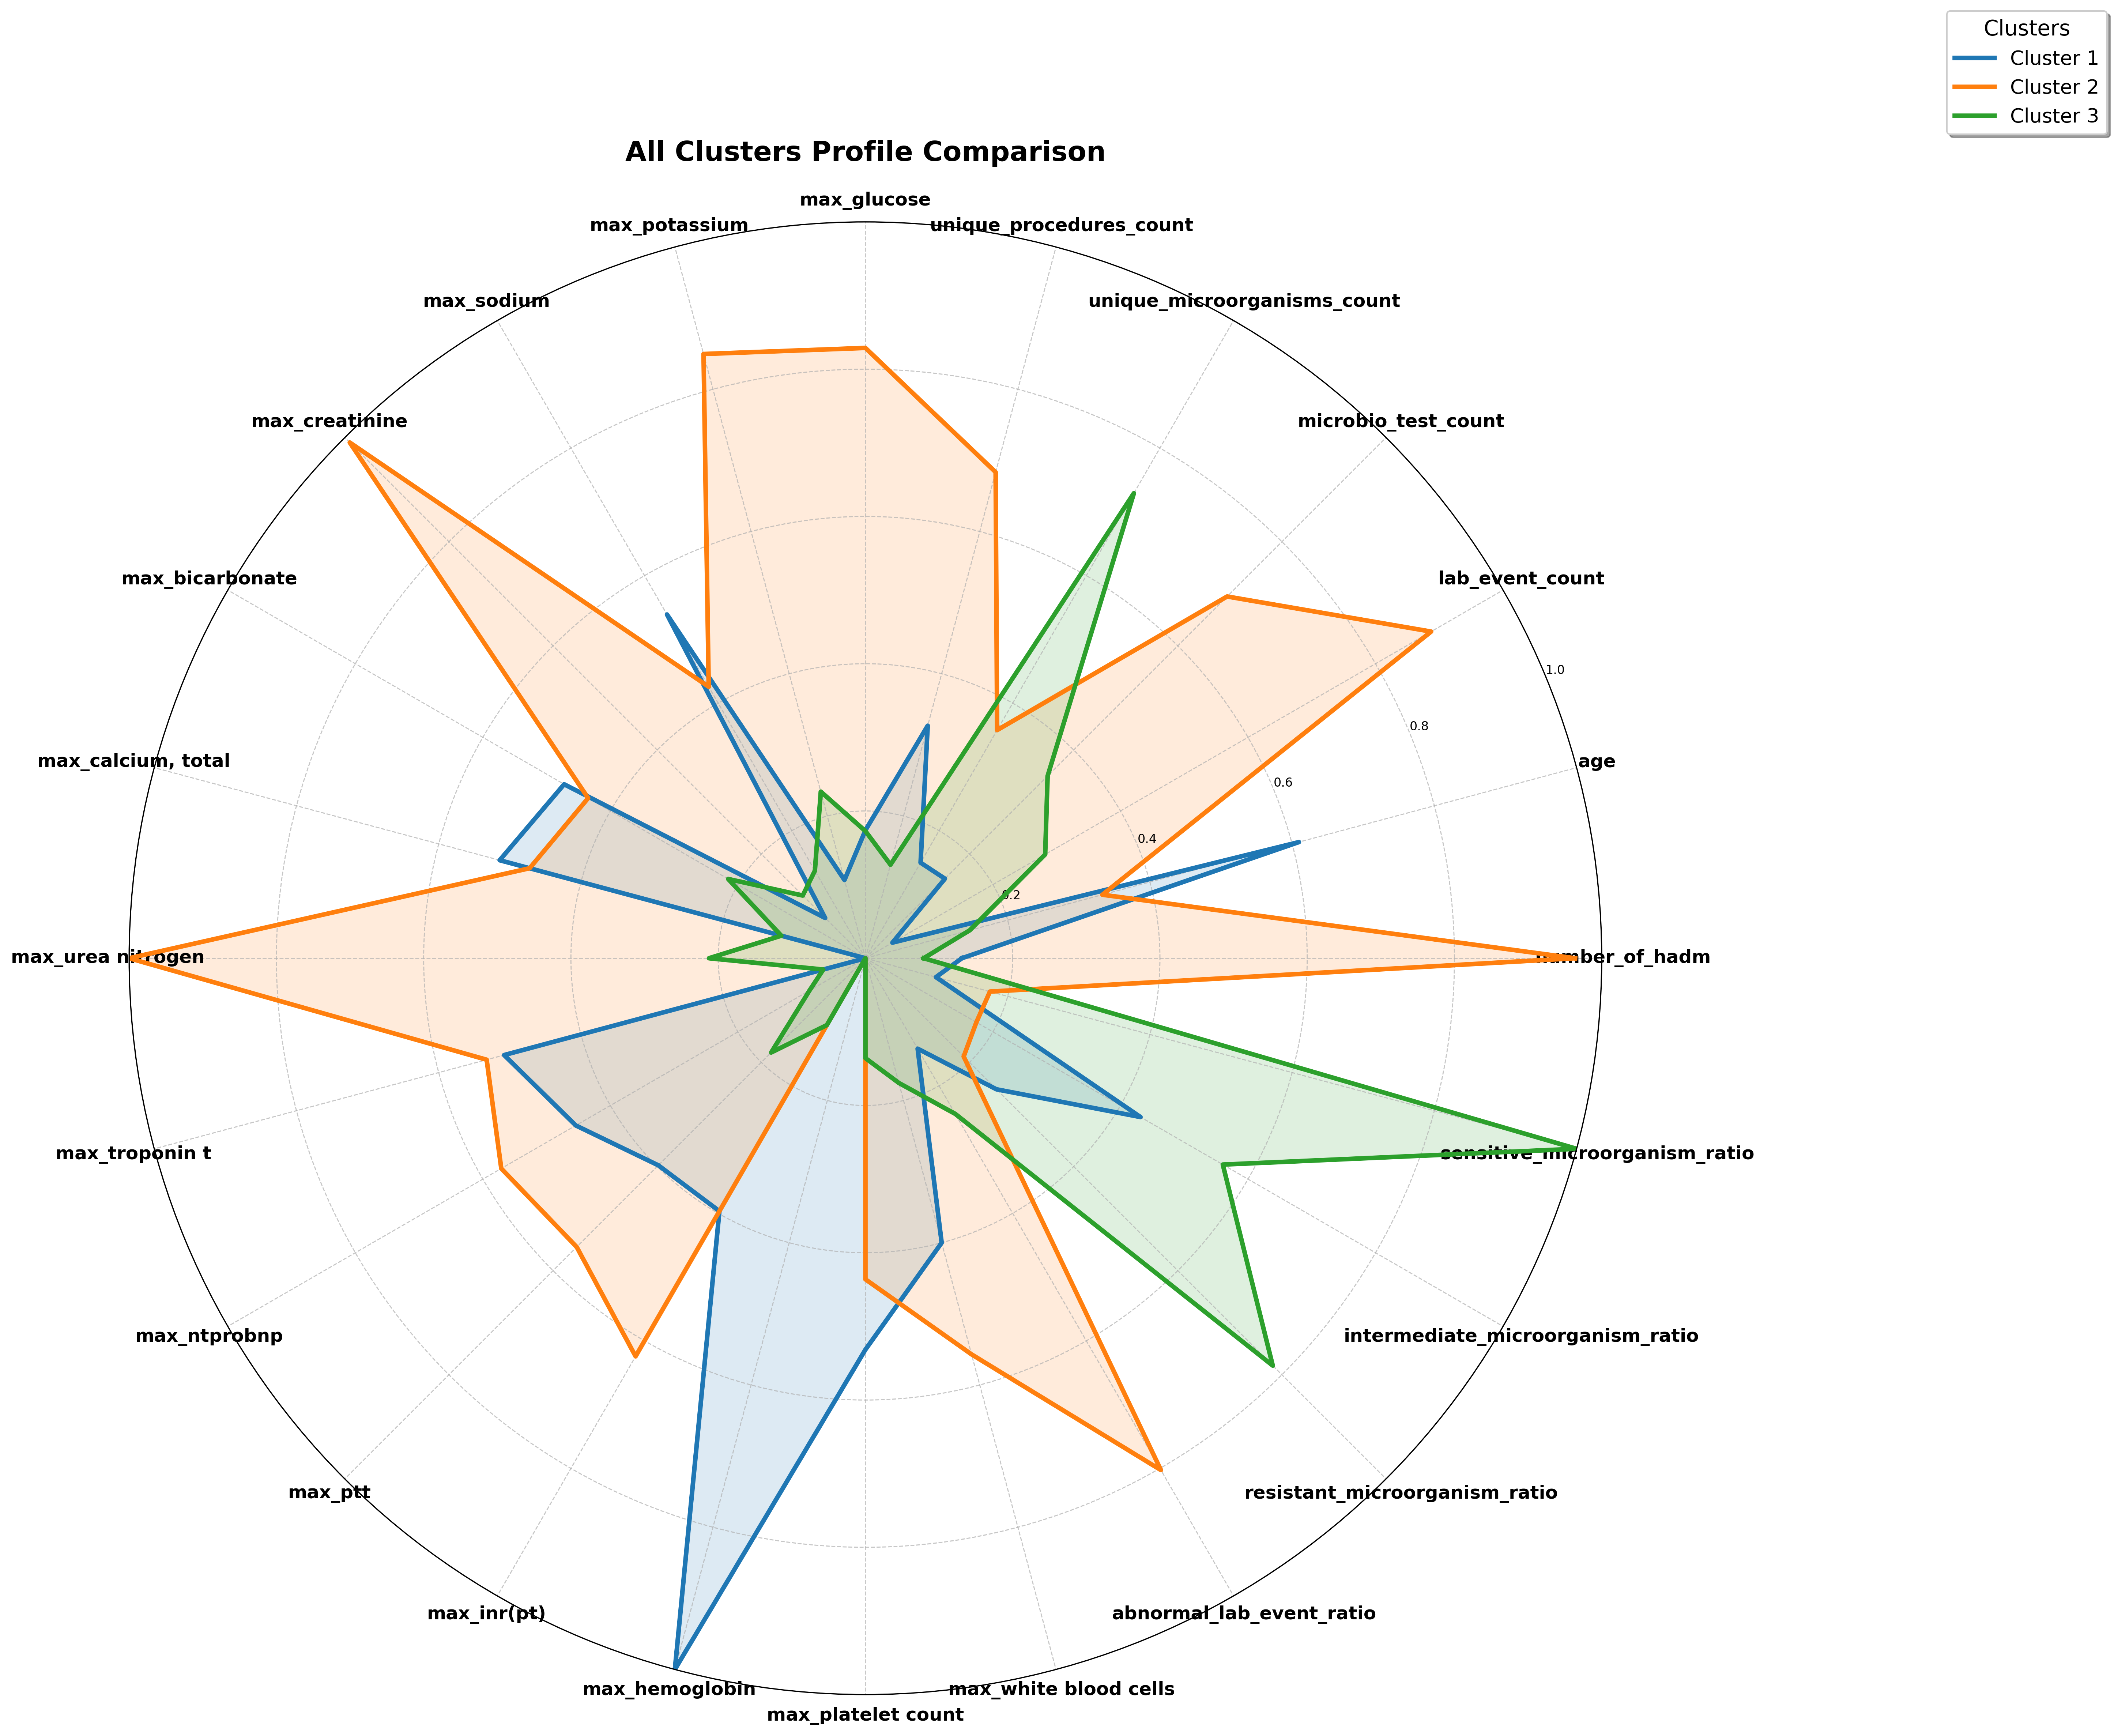

In [57]:
from math import pi
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import MinMaxScaler

# Number of features
N = len(feature_names)

# Get number of clusters
n_clusters = len(centers)

# Normalizza i centri tra 0 e 1 per il radar chart
scaler_radar = MinMaxScaler()
centers_normalized = scaler_radar.fit_transform(centers.T).T

# Create a color palette with exactly n_clusters colors
if n_clusters <= 10:
    colors_list = plt.cm.tab10(np.linspace(0, 1, 10))[:n_clusters]
else:
    colors_list = plt.cm.tab20(np.linspace(0, 1, 20))[:n_clusters]

# Create ONE radar plot with all clusters overlapped
fig = plt.figure(figsize=(20,20), dpi=300)
ax = plt.subplot(111, polar=True)

# Calculate angles for each feature
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Complete the circle

# Draw one axis per variable and add labels with better visibility
plt.xticks(angles[:-1], feature_names, color='black', size=12, fontweight='bold')

# Plot all clusters on the same radar chart
for i in range(len(centers_normalized)):
    values = centers_normalized[i].tolist()
    values += values[:1]  # Complete the circle
    
    # Plot data with unique color for each cluster
    ax.plot(angles, values, linewidth=3, linestyle='solid', 
            label=f'Cluster {i+1}', color=colors_list[i])
    
    # Fill area with the same color
    ax.fill(angles, values, alpha=0.15, color=colors_list[i])

# Set y-axis limits
ax.set_ylim(0, 1)

# Increase y-axis tick label size
ax.tick_params(axis='y', labelsize=8)

# Add title
ax.set_title('All Clusters Profile Comparison', size=18, fontweight='bold', pad=40)

# Add legend
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=13, 
           title='Clusters', title_fontsize=14, frameon=True, shadow=True)

# Add grid
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)

plt.tight_layout()
plt.show()


Number of subjects in each cluster:
Cluster 1: 3097 subjects
Cluster 2: 954 subjects
Cluster 3: 332 subjects


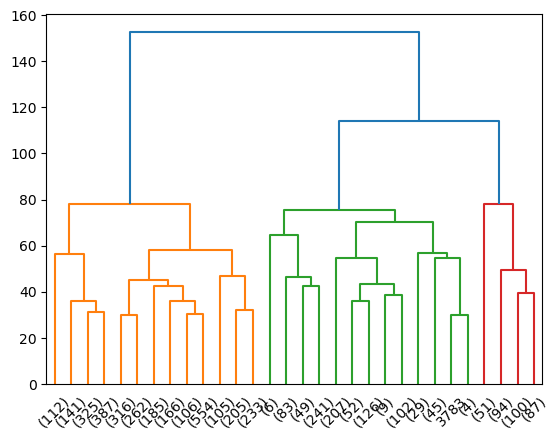

In [58]:
# Calculate the threshold based on optimal_k
# Get the linkage distances
distances = data_link[:, 2]
# Find the threshold that gives us optimal_k clusters
threshold_index = len(data_link) - used_k + 1
color_threshold = data_link[threshold_index, 2] if threshold_index < len(data_link) else data_link[-1, 2]

res = dendrogram(
    data_link, 
    color_threshold=color_threshold,
    truncate_mode='lastp',
)

# Print the number of subjects in each cluster
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
profile_df['cluster'] = cluster_labels
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print("\nNumber of subjects in each cluster:")
for cluster_id, count in cluster_counts.items():
    print(f"Cluster {cluster_id}: {count} subjects")    


# Plots

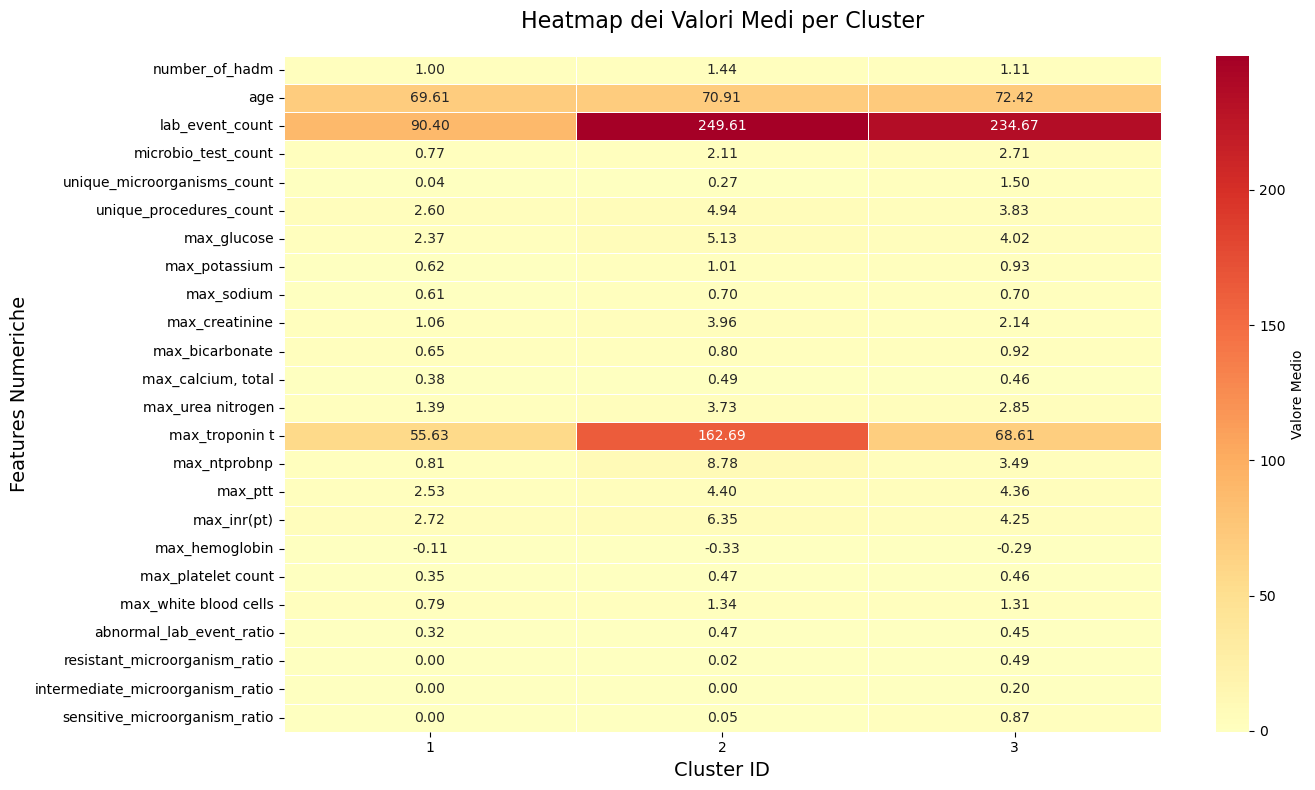

In [59]:
# Calcola le medie per cluster (escludendo subject_id e cluster)
numeric_cols_analysis = [col for col in numeric_cols if col not in ['subject_id', 'cluster']]
cluster_means = profile_df.groupby('cluster')[numeric_cols_analysis].mean()

# Crea la heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(cluster_means.T, annot=True, fmt='.2f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Valore Medio'}, linewidths=0.5, center=0.5)
plt.title('Heatmap dei Valori Medi per Cluster', fontsize=16, pad=20)
plt.xlabel('Cluster ID', fontsize=14)
plt.ylabel('Features Numeriche', fontsize=14)
plt.tight_layout()
plt.show()

In [61]:
#save the column cluster in the profile
labels = cluster_labels
profile_df['cluster'] = labels
profile_df


,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,cluster
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.251724,0.328571,0.410714,0.0,0.0,0.0,2
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.389655,0.714286,0.375000,0.0,0.0,0.0,1
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.341379,0.500000,0.384058,0.0,0.0,0.0,1
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.396552,0.357143,0.300000,0.0,0.0,0.0,1
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.220000,1.416667,0.375000,0.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1


In [62]:
#percentage of each desease in each cluster
disease_cols = ['ACS_acute_ischemic','Chronic_ischemic','Heart_failure','Valvular_nonrheumatic','Myocarditis_or_cardiomyopathy','Pericardial_disease','Endocarditis','Cardiac_arrest','Arrhythmias_or_conduction']
disease_summary = profile_df.groupby('cluster')[disease_cols].mean() * 100  
disease_summary

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction
cluster,,,,,,,,,
1,30.868582,14.949952,25.347110,5.166290,1.226994,5.779787,0.839522,0.000000,15.854052
2,38.888889,13.626834,41.299790,7.651992,1.153040,3.983229,0.628931,0.104822,12.997904
3,30.722892,11.144578,34.939759,10.843373,0.000000,3.915663,1.807229,0.301205,12.349398


In [63]:
#  valori della troponina in ogni cluster
troponin_summary = profile_df.groupby('cluster')['max_troponin t'].describe()
troponin_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
1,3097.0,55.625121,165.009196,0.0,0.0,0.0,21.00,1900.0
2,954.0,162.694969,404.261570,0.0,0.0,13.0,111.00,4130.0
3,332.0,68.605422,153.569211,0.0,0.0,6.0,50.25,1024.0


In [64]:
#valori del nt-proBNP in ogni cluster
nt_summary = profile_df.groupby('cluster')['max_ntprobnp'].describe()
nt_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
1,3097.0,0.806179,3.751646,0.0,0.0,0.0,0.0,52.913978
2,954.0,8.776038,30.756513,0.0,0.0,0.0,0.0,407.881720
3,332.0,3.485110,11.706305,0.0,0.0,0.0,0.0,106.601770


In [65]:
#valore del inr_ptt in ogni cluster
pt_summary = profile_df.groupby('cluster')['max_inr(pt)'].describe()
pt_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
1,3097.0,2.715935,4.272289,-0.5,0.5,1.0,2.500,43.0
2,954.0,6.353249,9.098358,0.0,1.5,2.5,9.000,109.5
3,332.0,4.246988,5.073849,0.0,1.5,2.0,5.125,35.5


## Age vs Number of admission scatter plot

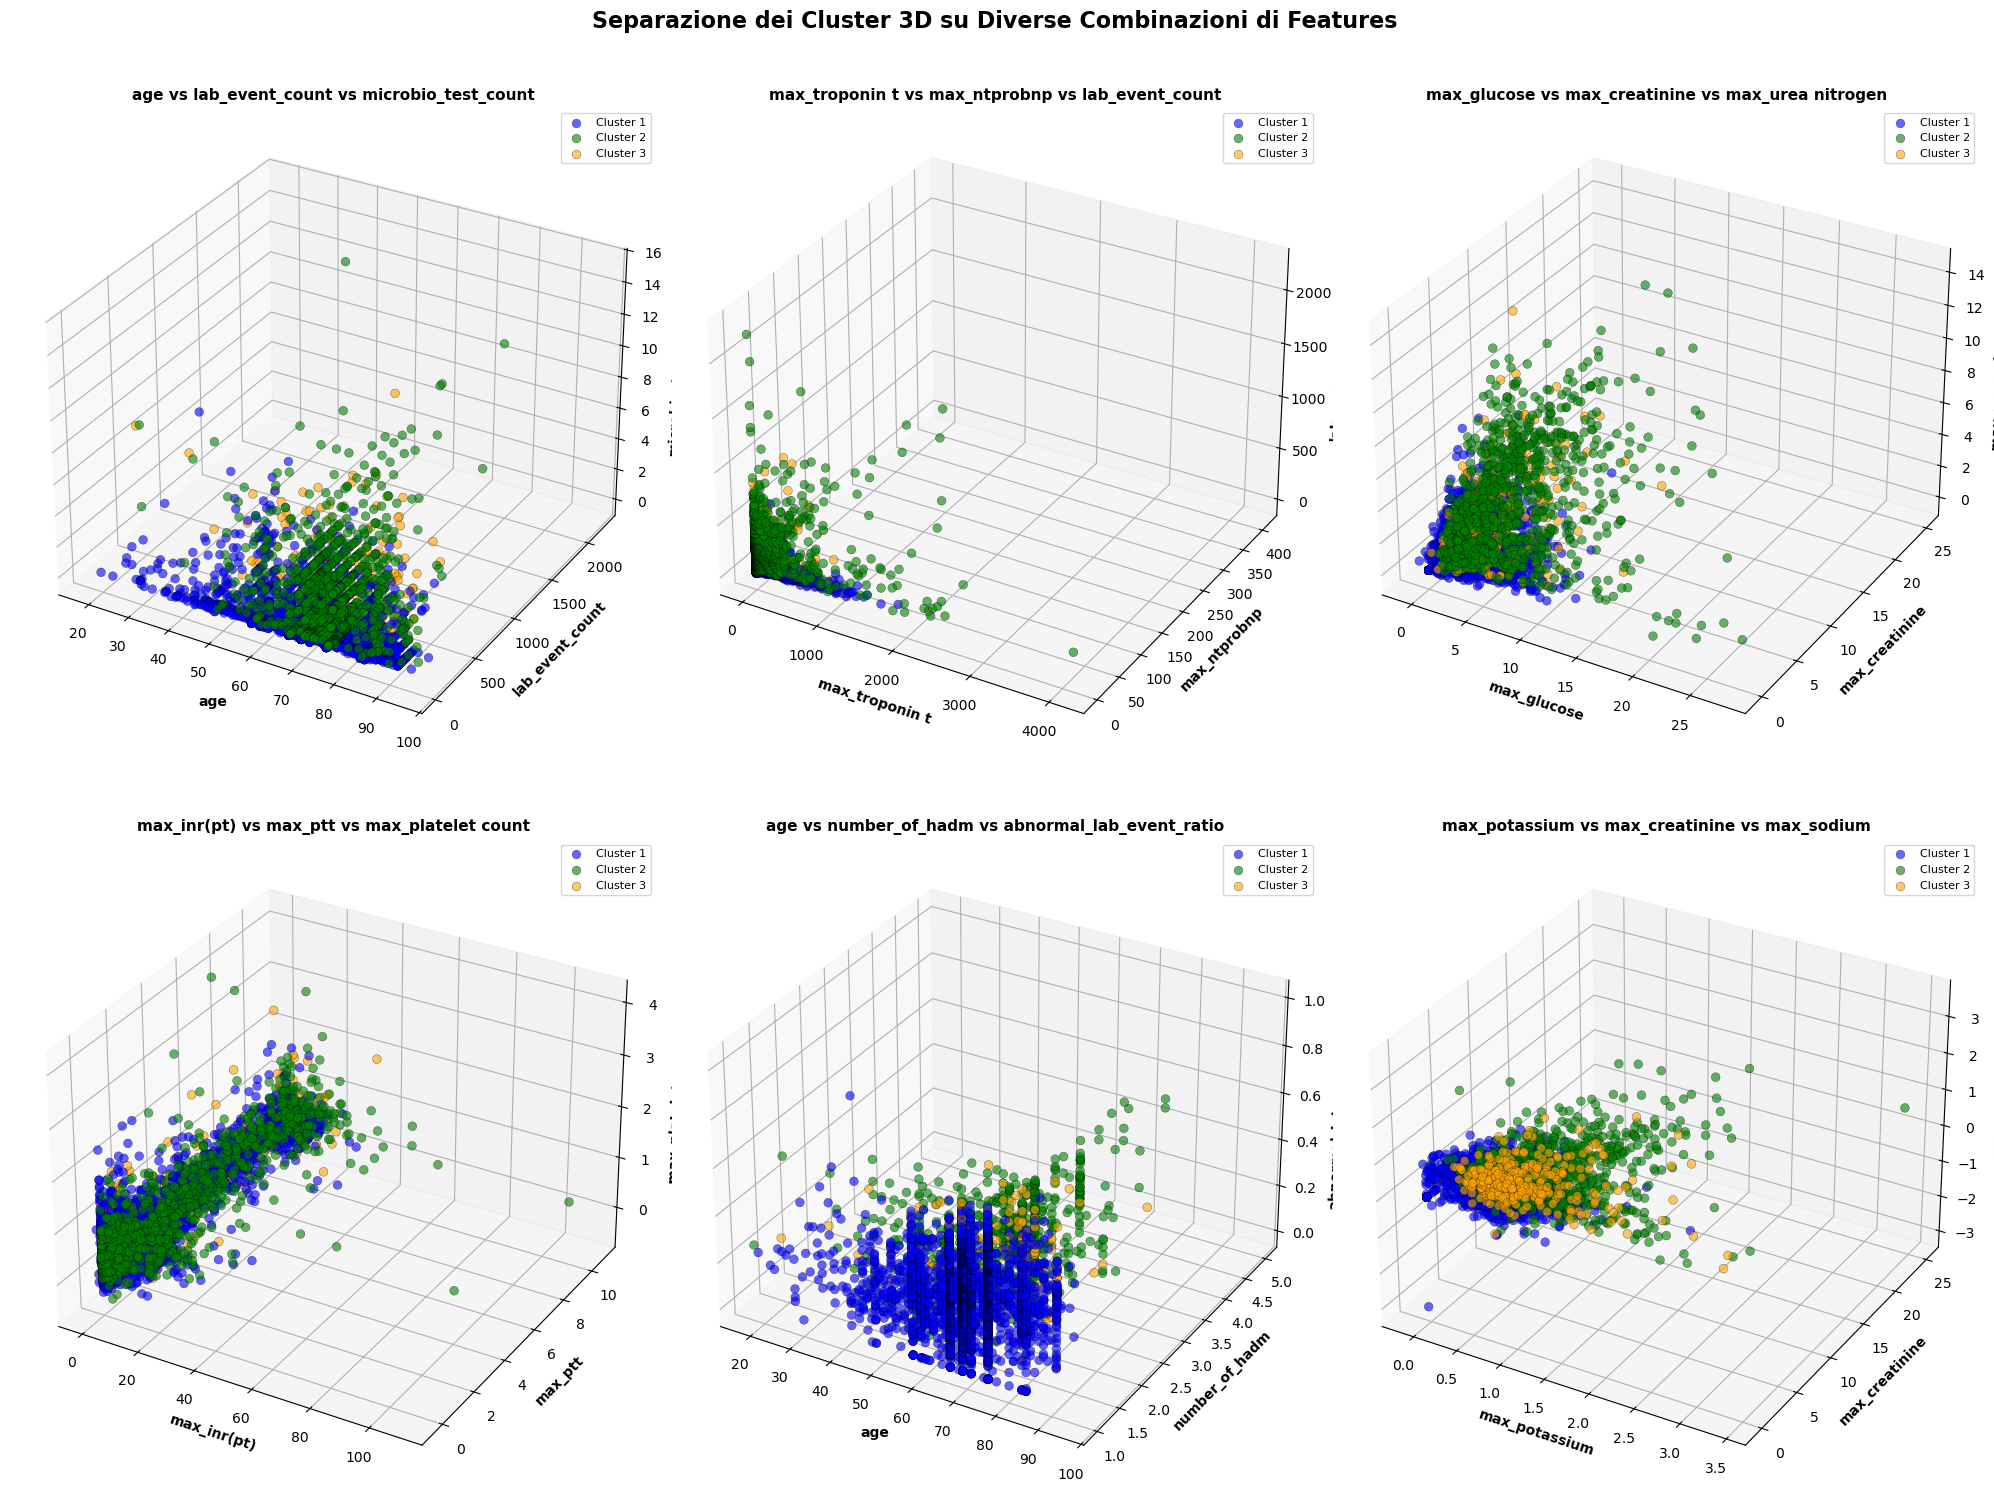

In [70]:
# Scatter plot 3D con diverse combinazioni di features
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(20, 16))

# Definisci le triple di features da visualizzare
triples = [
    ("age", "lab_event_count", "microbio_test_count"),
    ("max_troponin t", "max_ntprobnp", "lab_event_count"),
    ("max_glucose", "max_creatinine", "max_urea nitrogen"),
    ("max_inr(pt)", "max_ptt", "max_platelet count"),
    ("age", "number_of_hadm", "abnormal_lab_event_ratio"),
    ("max_potassium", "max_creatinine", "max_sodium"),
]

# Mappa colori per cluster
colors_map = {1: 'blue', 2: 'green', 3: 'orange', 4: 'purple', 5: 'red'}

for idx, (feat_x, feat_y, feat_z) in enumerate(triples):
    ax = fig.add_subplot(2, 3, idx + 1, projection='3d')
    
    for cluster_id in sorted(profile_df['cluster'].unique()):
        cluster_data = profile_df[profile_df['cluster'] == cluster_id]
        label = f'Cluster {cluster_id}'
        color = colors_map.get(cluster_id, 'gray')
        
        ax.scatter(cluster_data[feat_x], cluster_data[feat_y], cluster_data[feat_z],
                   label=label, alpha=0.6, s=40, c=color, edgecolors='k', linewidth=0.3)
    
    ax.set_xlabel(feat_x, fontsize=10, fontweight='bold')
    ax.set_ylabel(feat_y, fontsize=10, fontweight='bold')
    ax.set_zlabel(feat_z, fontsize=10, fontweight='bold')
    ax.set_title(f'{feat_x} vs {feat_y} vs {feat_z}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8, loc='best')
    ax.grid(True, alpha=0.3)

plt.suptitle('Separazione dei Cluster 3D su Diverse Combinazioni di Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()